In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## data-mixture

**Figure 1: Pretraining data mixture over the three-stage curriculum.** Each band is a domain's share of the tokens at each step; the stages switch at 30k and 70k steps. The web share falls from 62% to 40%, while code grows from 12% to 24% and math from 6% to 18%.

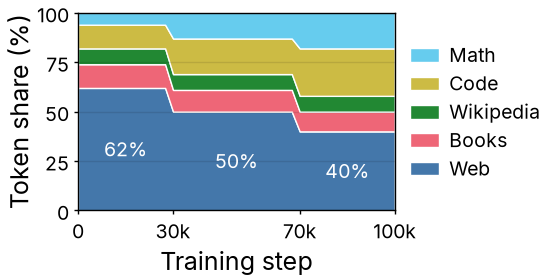

In [2]:
with open("../data/data-mixture.json") as f:
    data = json.load(f)
steps = np.array(data["steps"])
names = list(data["shares"])  # Web, Books, Wikipedia, Code, Math: the largest part at the bottom
shares = [data["shares"][name] for name in names]
series_colors = [colors[f"series-{i + 1}"] for i in range(len(names))]

fig, ax = plt.subplots(figsize=(2.75, 2))
ax.stackplot(steps, shares, colors=series_colors, labels=names, edgecolor="white", linewidth=0.5)

web = data["shares"]["Web"]
for start, end in [(0, 30000), (30000, 70000), (70000, 100000)]:
    share = web[list(steps).index(start)]
    ax.text((start + end) / 2, share / 2, f"{share:.0%}", ha="center", va="center", color="white")

ax.set_ylim(0, 1)
ax.margins(x=0)
ax.set_xticks([0, 30000, 70000, 100000], labels=["0", "30k", "70k", "100k"])
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], labels=["0", "25", "50", "75", "100"])
ax.set_xlabel("Training step")
ax.set_ylabel("Token share (%)")
ax.set_axisbelow(False)
ax.grid(axis="x", visible=False)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/data-mixture.pdf")
fig.savefig("../outputs/data-mixture.png")
plt.show()